# Заняття 12 · Demo 4 — mid і late fusion, абляції та чесна оцінка на реальних парах

Ті самі дані й ваги, що в Demo 3 (LLVIP + FLIR-aligned, `_cache12/`), плюс mid two-stream (два енкодери, concat + 1×1
на кожному рівні), early з аугментацією зсувом T і late fusion — WBF точкових детекцій RGB- і T-моделей.

1. Late: NMS проти WBF.
2. Таблиця «умова × модальність» з bootstrap-CI і парний bootstrap для приростів.
3. Похибка реєстрації: зсув T у обидва боки по обох осях — хто ламається першим і чи рятує аугментація.
4. Відмова модальності: T = 0 / RGB = 0.
5. Ціна: параметри, MAC, час на кадр.

In [1]:
%matplotlib inline
import sys, time, numpy as np, matplotlib.pyplot as plt, torch
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import fuse12 as F, panels as P
plt.rcParams['figure.dpi'] = 90
data = F.load_data()
REAL = isinstance(data, F.RealData)
names = ('RGB', 'T', 'early 4-ch', 'early + dropout', 'early + shift', 'mid two-stream')
models = {k: F.get_model(k, data) for k in names}
L = F.label

train 4070 пар (2005 LLVIP, 2065 FLIR), test 1879 пар; людей train 9310, test 5904 (+319 у зоні ігнору); 48 с
RGB              — з кешу real1_RGB.pt
T                — з кешу real1_T.pt
early 4-ch       — з кешу real1_early_4-ch.pt
early + dropout  — з кешу real1_early_p_dropout.pt


early + shift    — навчено за 348.3 с, параметрів 57,137


mid two-stream   — навчено за 447.0 с, параметрів 61,649


## 1. Late fusion: NMS проти WBF
NMS залишає точку з найбільшим score і викидає решту: координати не уточнюються, детекція однієї моделі має повну вагу.
WBF усереднює координати за score і ділить score на кількість моделей — одинока детекція штрафується.

In [2]:
X = data.Xte
d_rgb = F.decode(F.predict_heat(models['RGB'], X)); d_t = F.decode(F.predict_heat(models['T'], X))
late = {'late NMS': [F.nms_points([a, b]) for a, b in zip(d_rgb, d_t)],
        'late WBF': [F.wbf_points([a, b]) for a, b in zip(d_rgb, d_t)]}
for k, d in late.items():
    print(f'{k:9s}: ' + ', '.join(f'{L(c)} {F.average_precision(d, data.Cte, np.where(data.cond == c)[0], ign=data.Ite):.3f}'
                                  for c in data.conds) + f', all {F.average_precision(d, data.Cte, ign=data.Ite):.3f}')

late NMS : LLVIP ніч 0.565, LLVIP день 0.563, FLIR ніч 0.365, FLIR день 0.243, all 0.339


late WBF : LLVIP ніч 0.617, LLVIP день 0.611, FLIR ніч 0.392, FLIR день 0.253, all 0.390


## 2. Умова × модальність, 95 % bootstrap-CI
Одне число AP ховає, що день і ніч поводяться протилежно. CI — за перевибіркою тестових кадрів.

In [3]:
res, dets = F.evaluate({k: models[k] for k in names}, data)
rows = ['RGB', 'T', 'late WBF', 'early 4-ch', 'early + dropout', 'early + shift', 'mid two-stream']
print(f'{"модель":16s} ' + ' '.join(f'{L(c):>19s}' for c in data.conds) + f' {"all":>7s}')
for k in rows:
    cells = []
    for c in data.conds:
        idx = np.where(data.cond == c)[0]; lo, hi = F.bootstrap_ap(dets[k], data.Cte, idx, n_boot=200, ign=data.Ite)
        cells.append(f'{res[k][c]:.3f} [{lo:.2f}–{hi:.2f}]')
    print(f'{k:16s} ' + ' '.join(f'{s:>19s}' for s in cells) + f' {res[k]["all"]:7.3f}')
print({c: int((data.cond == c).sum()) for c in data.conds}, '— тестових кадрів на умову')

модель                     LLVIP ніч          LLVIP день            FLIR ніч           FLIR день     all


RGB                0.256 [0.24–0.28]   0.363 [0.31–0.44]   0.123 [0.10–0.15]   0.206 [0.19–0.23]   0.174


T                  0.642 [0.61–0.67]   0.544 [0.49–0.61]   0.357 [0.31–0.39]   0.143 [0.12–0.16]   0.369


late WBF           0.617 [0.59–0.64]   0.611 [0.56–0.67]   0.392 [0.36–0.42]   0.253 [0.23–0.27]   0.390


early 4-ch         0.683 [0.66–0.70]   0.592 [0.54–0.65]   0.383 [0.35–0.42]   0.195 [0.18–0.21]   0.420


early + dropout    0.648 [0.62–0.67]   0.624 [0.57–0.69]   0.423 [0.39–0.46]   0.214 [0.19–0.24]   0.415


early + shift      0.657 [0.63–0.68]   0.623 [0.57–0.68]   0.358 [0.33–0.39]   0.222 [0.20–0.24]   0.408


mid two-stream     0.630 [0.61–0.65]   0.483 [0.44–0.54]   0.424 [0.39–0.46]   0.221 [0.20–0.24]   0.402
{'llvip_night': 733, 'llvip_day': 133, 'flir_night': 309, 'flir_day': 704} — тестових кадрів на умову


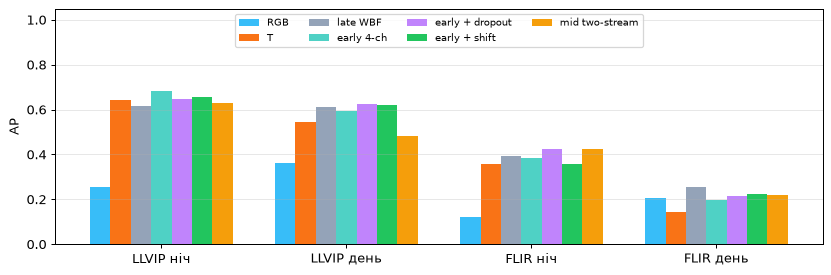

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.4))
nc, w = len(data.conds), 0.11
cols = (P.C_RGB, P.C_T, '#94A3B8', P.C_F, '#C084FC', '#22C55E', '#F59E0B')
for j, k in enumerate(rows):
    ax.bar(np.arange(nc) + (j - 3) * w, [res[k][c] for c in data.conds], w, label=k, color=cols[j])
ax.set_xticks(range(nc)); ax.set_xticklabels([L(c) for c in data.conds]); ax.set_ylabel('AP'); ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, ncol=4, loc='upper center'); ax.grid(alpha=0.3, axis='y'); plt.show()

### Приріст — парним bootstrap
Два CI, що перекриваються, ще не означають «різниці немає», а два, що не перекриваються, — складний спосіб сказати «є».
Правильно — перевибирати **ті самі** кадри для обох моделей і дивитися CI різниці: якщо він не містить 0, приріст є.

In [5]:
for c in data.conds:
    idx = np.where(data.cond == c)[0]
    best = 'RGB' if res['RGB'][c] > res['T'][c] else 'T'
    for a, b in (('early 4-ch', best), ('mid two-stream', 'early 4-ch'), ('early + dropout', 'early 4-ch')):
        d, (lo, hi) = F.paired_bootstrap(dets[a], dets[b], data.Cte, idx, ign=data.Ite)
        verdict = 'є' if lo > 0 else ('гірше' if hi < 0 else 'не доведено')
        print(f'{L(c):10s} {a:15s} − {b:10s}: {d:+.3f}  CI [{lo:+.3f}, {hi:+.3f}]  → {verdict}')

LLVIP ніч  early 4-ch      − T         : +0.040  CI [+0.021, +0.060]  → є


LLVIP ніч  mid two-stream  − early 4-ch: -0.053  CI [-0.073, -0.031]  → гірше


LLVIP ніч  early + dropout − early 4-ch: -0.034  CI [-0.052, -0.016]  → гірше


LLVIP день early 4-ch      − T         : +0.048  CI [-0.007, +0.095]  → не доведено


LLVIP день mid two-stream  − early 4-ch: -0.109  CI [-0.160, -0.050]  → гірше


LLVIP день early + dropout − early 4-ch: +0.032  CI [-0.011, +0.073]  → не доведено


... (2 outputs left out)

FLIR ніч   early + dropout − early 4-ch: +0.040  CI [+0.011, +0.066]  → є


FLIR день  early 4-ch      − RGB       : -0.011  CI [-0.037, +0.012]  → не доведено


FLIR день  mid two-stream  − early 4-ch: +0.026  CI [+0.007, +0.046]  → є


FLIR день  early + dropout − early 4-ch: +0.019  CI [+0.001, +0.037]  → є


## 3. Похибка реєстрації на тесті
Слайд «Реєстрація · ціна зсуву». T-канал зсуваємо на `d` px сітки 160×128 відносно RGB і розмітки (розмітка — у кадрі RGB).
Один px сітки — це 4 px нативного кадру FLIR (640×512) і 8 px LLVIP (1280×1024). Людина на цій сітці — 6–40 px заввишки.
`early + shift` навчалась із випадковим зсувом T у ±2 px по обох осях — та сама ідея, що й modality dropout.

зсув T по x, px:     -4     -3     -2     -1      0      1      2      3      4
T                 0.199  0.247  0.299  0.354  0.369  0.367  0.347  0.293  0.251
late WBF          0.265  0.299  0.343  0.375  0.390  0.387  0.370  0.328  0.294
early 4-ch        0.220  0.268  0.328  0.367  0.420  0.397  0.365  0.303  0.268
early + shift     0.250  0.309  0.368  0.411  0.408  0.425  0.394  0.362  0.304
mid two-stream    0.208  0.259  0.325  0.376  0.402  0.408  0.381  0.321  0.284
RGB (не залежить від зсуву) 0.174
по діагоналі (d, d), d = 2 / 3: early 4-ch 0.330 / 0.241; early + shift 0.373 / 0.309


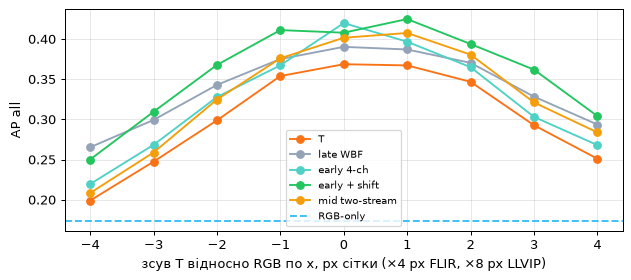

In [6]:
shifts = [-4, -3, -2, -1, 0, 1, 2, 3, 4]
keys = ('T', 'late WBF', 'early 4-ch', 'early + shift', 'mid two-stream')
curve = {k: [] for k in keys}
sub = {k: models[k] for k in ('RGB', 'T', 'early 4-ch', 'early + shift', 'mid two-stream')}
for s in shifts:
    r, _ = F.evaluate(sub, data, shift=(s, 0))
    for k in keys:
        curve[k].append(r[k]['all'])
diag = {k: [] for k in ('early 4-ch', 'early + shift')}
for s in (2, 3):
    r, _ = F.evaluate({k: models[k] for k in diag}, data, shift=(s, s), late=False)
    for k in diag:
        diag[k].append(r[k]['all'])
print('зсув T по x, px: ' + ' '.join(f'{s:>6d}' for s in shifts))
for k, v in curve.items():
    print(f'{k:16s} ' + ' '.join(f'{x:6.3f}' for x in v))
print(f'RGB (не залежить від зсуву) {res["RGB"]["all"]:.3f}')
print('по діагоналі (d, d), d = 2 / 3: ' + '; '.join(f'{k} {v[0]:.3f} / {v[1]:.3f}' for k, v in diag.items()))
fig, ax = plt.subplots(figsize=(8, 3.2))
for (k, v), c in zip(curve.items(), (P.C_T, '#94A3B8', P.C_F, '#22C55E', '#F59E0B')):
    ax.plot(shifts, v, 'o-', color=c, label=k)
ax.axhline(res['RGB']['all'], color=P.C_RGB, ls='--', label='RGB-only')
ax.set_xlabel('зсув T відносно RGB по x, px сітки' + (' (×4 px FLIR, ×8 px LLVIP)' if REAL else ''))
ax.set_ylabel('AP all'); ax.set_xticks(shifts); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

In [7]:
P.shift_panel({k: models[k] for k in ('RGB', 'T', 'early 4-ch', 'early + shift', 'mid two-stream')}, data);

interactive(children=(IntSlider(value=0, continuous_update=False, description='dx', max=6, min=-6), IntSlider(…

**Що бачимо.** Падіння AP від зсуву приблизно симетричне за знаком — важить модуль похибки, а не напрям. Зсув T шкодить
навіть T-only: розмітка лежить у кадрі RGB. Early і mid, навчені на вирівняних парах, втрачають найшвидше — мережа
навчилася довіряти T-координаті. Late деградує повільніше: зсунуті T-детекції стають хибними, RGB-гілка лишається.
Аугментація зсувом на train (±2 px) робить криву найпологішою ціною ~0.01 AP у нулі. На реальних даних усі fusion-моделі
навіть при ±4 px (16–32 px нативного кадру) лишаються вище за RGB-only — бо RGB тут слабкий (переважно ніч). Бюджет
реєстрації — ≤ 1 px на сітці мережі (≈ 4 px FLIR, 8 px LLVIP); реальна залишкова розбіжність «вирівняних» датасетів
(Demo 2, розділ 6) — порядку 1–2 px сітки, тож аугментація зсувом тут не розкіш.

## 4. Відмова модальності

In [8]:
print(f'{"модель":16s} {"повний":>8s} {"T = 0":>8s} {"RGB = 0":>8s}')
full, _ = F.evaluate(models, data, late=False)
no_t, _ = F.evaluate(models, data, drop='t', late=False)
no_rgb, _ = F.evaluate(models, data, drop='rgb', late=False)
for k in names:
    print(f'{k:16s} {full[k]["all"]:8.3f} {no_t[k]["all"]:8.3f} {no_rgb[k]["all"]:8.3f}')

модель             повний    T = 0  RGB = 0


RGB                 0.174    0.174    0.000
T                   0.369    0.000    0.369
early 4-ch          0.420    0.018    0.266
early + dropout     0.415    0.203    0.368
early + shift       0.408    0.050    0.268
mid two-stream      0.402    0.013    0.226


Early без dropout при T = 0 падає майже до нуля — нижче за RGB-only, хоча RGB-канали на місці. Mid two-stream і early
з аугментацією зсувом — так само: стійкість до зникнення модальності дає лише навчання з її зникненням. Dropout повертає
early вище за RGB-only при T = 0 і краще за всіх тримає RGB = 0, майже без ціни на повному вході. Late fusion отримує цю
стійкість «безкоштовно»: зникла модальність — це просто один детектор.

## 5. Ціна

In [9]:
def macs(model):
    tot = 0
    def hook(m, i, o):
        nonlocal tot
        if isinstance(m, torch.nn.Conv2d):
            tot += o.numel() * m.in_channels // m.groups * m.kernel_size[0] * m.kernel_size[1]
    hs = [m.register_forward_hook(hook) for m in model.modules()]
    with torch.no_grad():
        model(torch.zeros(1, 4, *data.size))
    for h in hs:
        h.remove()
    return tot

x = data.Xte[:256].float()
print(f'{"модель":16s} {"параметри":>10s} {"MAC/кадр":>10s} {"CPU мс / 256 кадрів":>20s}')
for k in ('RGB', 'T', 'early 4-ch', 'mid two-stream'):
    m = models[k]
    with torch.no_grad():
        m(x); t0 = time.perf_counter()
        for _ in range(5):
            m(x)
    print(f'{k:16s} {F.n_params(m):10,d} {macs(m) / 1e6:9.2f}M {(time.perf_counter() - t0) / 5 * 1e3:20.1f}')
print('late = RGB + T: сума параметрів і MAC двох моделей')

модель            параметри   MAC/кадр  CPU мс / 256 кадрів


RGB                  57,065     65.37M                666.2


T                    56,921     62.42M                659.1


early 4-ch           57,137     66.85M                685.4


mid two-stream       61,649     72.99M                968.7
late = RGB + T: сума параметрів і MAC двох моделей


## Питання

1. Для якої умови приріст early над кращою одномодальною моделлю не доведено парним bootstrap? Що це означає для звіту треку 3?
2. Late WBF програє early на повному вході, але виграє при великому зсуві. Яку з двох поставите на платформу з side-by-side
   гімбалом без глибини?
3. Аугментація зсувом коштує трохи AP у нулі. Як вибрати її амплітуду, знаючи розподіл похибки реєстрації з Demo 2?
4. Чому таблиця на 160×128 занижує AP далеких людей порівняно з детектором на повній роздільності?